# Буткемп, электронный relative-value трейдинг, день 15 — reservation price и optimal width

Лабораторная дня: откалибровать входы модели Avellaneda–Stoikov на своём инструменте, посчитать reservation price и оптимальную ширину и честно сравнить ширину модели с шириной, которая была бы прибыльна ex post, в бакетах по волатильности. Оценивается пункт 3 — сравнение по режимам и знак ошибки.

Инструмент: BTC-USDT на Bybit, 100-мс top-of-book и трейды **только BTCUSDT** за 2026-07-01 12:00–12:30 UTC. Тик 0.1; медианный спред — один тик, но встречаются и широкие (до 65 тиков), это надо держать в голове.

Формулы дня:

$$r=s-q\,\gamma\,\sigma^2\,(T-t),$$

$$\delta^a+\delta^b=\gamma\sigma^2(T-t)+\frac{2}{\gamma}\ln\!\left(1+\frac{\gamma}{k}\right),$$

$$\text{bid}=r-\frac{\text{width}}2,\qquad \text{ask}=r+\frac{\text{width}}2.$$

$s$ — mid, $q$ — инвентарь, $\gamma$ — risk aversion (фиксируем, не фитим), $\sigma$ — волатильность, $T-t$ — горизонт, $A,k$ — параметры $\lambda(\delta)=A e^{-k\delta}$.

**Единицы.** $\sigma$ и $T-t$ должны быть в согласованных единицах: здесь $\sigma$ — стандартное отклонение приращения mid **за один шаг 100 мс** (в тиках), а горизонт $T-t=H=100$ шагов (10 секунд), так что $\sigma^2(T-t)=\sigma_{\text{шаг}}^2\cdot H$. Единицы $\gamma$ обратны «инвентарь × дисперсия», поэтому число из примера на слайде нельзя переносить на другой инструмент: $\gamma$ задаётся допуском по инвентарю (см. ниже).

## Данные и горизонт

Горизонт экспозиции — **10 секунд** ($H=100$ шагов): котировка живёт 10 секунд, σ считаем по приращениям mid за шаг 100 мс и масштабируем на горизонт как $\sigma^2 H$, ширину — в тиках. Горизонт — выбранная конвенция (в круглосуточном рынке нет момента закрытия, Горизонт $T$ — строго модельная величина; его можно заменить бесконечным горизонтом или временем жизни инвентаря), поэтому ниже есть sweep по горизонту. Режимы (calm/normal/stress) задаём **расширяющимися** терцилями σ: в момент $t$ используем только прошлые значения, чтобы не было soft look-ahead в назначении режима.

In [1]:
import duckdb, numpy as np, pandas as pd, scipy.stats as st, os, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 40)

def _find_data_dir():
    "каталог с паркетами: HW_DATA_DIR, ./data, ../hft-bootcamp-data или Downloads"
    for p in (os.environ.get('HW_DATA_DIR'), './data', '../hft-bootcamp-data', '/Users/b.kotov/Downloads'):
        if p and os.path.exists(os.path.join(p, 'l2_executable_quotes_100ms_10000.parquet')):
            return p.rstrip('/\\') + '/'
    raise FileNotFoundError('положите паркеты (папка 1d_data из Slack) в ./data или задайте HW_DATA_DIR')

D = _find_data_dir()
Q = D + 'l2_executable_quotes_100ms_10000.parquet'
T0 = '2026-07-01 12:00:00+00'
T1 = '2026-07-01 12:30:00+00'
con = duckdb.connect()
panel = con.execute(f"""
    SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
    FROM read_parquet('{Q}')
    WHERE asset='BTC' AND exchange='Bybit'
      AND event_time >= TIMESTAMPTZ '{T0}' AND event_time < TIMESTAMPTZ '{T1}'
    ORDER BY event_time
""").df().reset_index(drop=True)
trades = con.execute(f"""
    SELECT event_time, price, amount
    FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
    WHERE symbol='BTCUSDT'
      AND event_time >= TIMESTAMPTZ '{T0}' AND event_time < TIMESTAMPTZ '{T1}'
    ORDER BY event_time
""").df()
tick = 0.1
mid = panel.mid.values; bb = panel.best_bid.values; ba = panel.best_ask.values
bba = panel.best_bid_amount.values; baa = panel.best_ask_amount.values
n = len(panel)
to_ns = lambda x: pd.DatetimeIndex(x).as_unit('ns').asi8
pt = to_ns(panel.event_time); tt = to_ns(trades.event_time)
ib = np.searchsorted(pt, tt, side='right') - 1
ok = (ib >= 0) & (ib < n); ib = ib[ok]
trades = trades.iloc[np.where(ok)[0]].reset_index(drop=True)
tp = trades.price.to_numpy(); ta = trades.amount.to_numpy()
print('панель: %d шагов, %s .. %s' % (n, panel.event_time.iloc[0], panel.event_time.iloc[-1]))
print('трейдов BTCUSDT в окне:', len(trades))
print('спред, тиков: median %.2f, p95 %.2f, max %.2f' % (
    np.median((ba-bb)/tick), np.quantile((ba-bb)/tick, .95), ((ba-bb)/tick).max()))

панель: 17233 шагов, 2026-07-01 15:00:00.086503+03:00 .. 2026-07-01 15:29:59.945617+03:00
трейдов BTCUSDT в окне: 66466
спред, тиков: median 1.00, p95 1.00, max 65.00


## σ и режимы

σ — скользящее (окно 100 шагов) стандартное отклонение приращений mid **за один шаг 100 мс**, в тиках; на горизонте 10 секунд дисперсия при случайном блуждании равна $\sigma^2\cdot 100$. Режимы — expanding-терцили: в каждый момент пороги считаются по прошлому (минимум 600 шагов прогрева), поэтому режим не подглядывает в будущее. Для контроля печатается и эмпирическая σ 10-секундных приращений.

In [2]:
H_STEPS = 100                       # горизонт экспозиции котировки: 10 с = 100 шагов по 100 мс
ret = np.diff(mid, prepend=mid[0])
sig = pd.Series(ret).rolling(100).std().values / tick        # σ НА ШАГ 100 мс, тиков; на горизонте H шагов дисперсия = σ²·H
s = pd.Series(sig)
q1 = s.expanding(min_periods=600).quantile(1/3).values
q2 = s.expanding(min_periods=600).quantile(2/3).values
reg = np.where(sig <= q1, 0, np.where(sig <= q2, 1, 2))
reg = np.where(np.isnan(q1), 1, reg)
names = {0: 'calm', 1: 'normal', 2: 'stress'}
d10 = pd.Series(np.r_[np.full(100, np.nan), mid[100:] - mid[:-100]])
sig10_emp = d10.rolling(1000).std().values / tick            # эмпирическая σ 10-секундных приращений (окно 100 с), тиков
print('σ на шаг 100 мс (тиков): median %.2f, p90 %.2f, max %.2f' % (
    np.nanmedian(sig), np.nanquantile(sig, .9), np.nanmax(sig)))
print('σ на горизонте 10 с = σ_шаг·√100 (тиков): median %.1f; эмпирическая σ 10-секундных приращений: median %.1f' % (
    np.nanmedian(sig)*10, np.nanmedian(sig10_emp)))
print('средняя σ на шаг по режимам:', {names[r]: round(float(np.nanmean(sig[reg==r])), 2) for r in range(3)})
print('доля времени:', {names[r]: round(float(np.mean(reg==r)), 2) for r in range(3)})

σ на шаг 100 мс (тиков): median 9.82, p90 19.97, max 46.55
σ на горизонте 10 с = σ_шаг·√100 (тиков): median 98.2; эмпирическая σ 10-секундных приращений: median 141.3
средняя σ на шаг по режимам: {'calm': 5.23, 'normal': 10.89, 'stress': 18.91}
доля времени: {'calm': 0.39, 'normal': 0.32, 'stress': 0.29}


## Fill log: котировки на разных расстояниях

Живого fill-лога нет, поэтому строим контрфактический лог на реальных трейдах: каждые 10 секунд ставим пару котировок на расстоянии $d-1$ тиков от touch (при $d=1$ — на touch) и держим 10 секунд. Покупка может исполниться, если трейд прошёл по нашей цене и лучшая цена не ушла выше нашей; вероятность филла по самому крупному такому трейду — $p=\min(1,\ \text{trade size}/\text{размер touch-очереди})$ (очередь берётся на момент трейда, одинаково для всех $d$; позиция в очереди не моделируется).

**Оценки без шума розыгрыша.** Раньше филл разыгрывался Bernoulli, и в ячейке оставалось 1–3 исполнения. Теперь fill rate — среднее $p$, а markout усредняется с весами $p$: $\text{mark}=\sum p\cdot\text{mark}_i/\sum p$ (markout считается для каждого окна «как если бы исполнили»). Розыгрыш сохранён в колонке `filled` для сравнения. Markout — через 10 секунд после постановки, в тиках; он включает наш edge $d$ и неблагоприятное движение mid. Комиссия — 0.1 bp maker (допущение, не cited), переведённая в тики; на BTC с тиком 0.1 это заметная величина (5.85 тика), она входит в ex-post net.

In [3]:
DELTAS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
STEP = 100
FEE = 0.1e-4 * float(np.nanmean(mid)) / tick
print('FEE = %.2f ticks (0.1 bp maker)' % FEE)

def build_fill_log(lifetime=100, step=100, seed=15, deltas=DELTAS, ctx=None):
    "Для каждого окна и расстояния d: вероятность филла p (по трейдам), розыгрыш Bernoulli и markout «если бы исполнили»."
    if ctx is None:
        ctx = dict(n=n, mid=mid, bb=bb, ba=ba, bba=bba, baa=baa, ib=ib, tp=tp, ta=ta, sig=sig, reg=reg)
    n_, mid_, bb_, ba_, bba_, baa_ = ctx['n'], ctx['mid'], ctx['bb'], ctx['ba'], ctx['bba'], ctx['baa']
    ib_, tp_, ta_, sig_, reg_ = ctx['ib'], ctx['tp'], ctx['ta'], ctx['sig'], ctx['reg']
    rng = np.random.default_rng(seed)
    rows = []
    for i in range(0, n_ - step - lifetime, step):
        if np.isnan(sig_[i]): continue
        r = int(reg_[i])
        j0 = np.searchsorted(ib_, i, 'left'); j1 = np.searchsorted(ib_, i + lifetime, 'left')
        kk = ib_[j0:j1]; px = tp_[j0:j1]; am = ta_[j0:j1]
        for d in deltas:
            bid = bb_[i] - (d - 1) * tick
            ask = ba_[i] + (d - 1) * tick
            mb = (np.abs(px - bid) <= tick/2) & (bb_[kk] <= bid + 1e-9)
            ms = (np.abs(px - ask) <= tick/2) & (ba_[kk] >= ask - 1e-9)
            pbuy = float(np.max(np.minimum(1.0, am[mb] / np.maximum(bba_[kk][mb], 1e-9)))) if mb.any() else 0.0
            psell = float(np.max(np.minimum(1.0, am[ms] / np.maximum(baa_[kk][ms], 1e-9)))) if ms.any() else 0.0
            for side, pr in (('B', pbuy), ('S', psell)):
                filled = bool(rng.random() < pr)
                mk = (mid_[i+lifetime] - bid)/tick if side == 'B' else (ask - mid_[i+lifetime])/tick
                rows.append({'w': i, 'd': d, 'reg': r, 'side': side, 'p': pr, 'filled': filled,
                             'mark_if': mk, 'markout': mk if filled else np.nan, 'sigma': sig_[i]})
    return pd.DataFrame(rows)

def agg_cells(f):
    "Ожидаемые оценки: fill rate = среднее p, markout = среднее по p (без шума розыгрыша), eff_fills = Σp."
    g = f.assign(pm=f.p * f.mark_if).groupby(['reg', 'd']).agg(
        n=('p', 'size'), fill=('p', 'mean'), eff_fills=('p', 'sum'), pm=('pm', 'sum'),
        drawn=('filled', 'sum')).reset_index()
    g['mark'] = np.where(g.eff_fills > 0, g.pm / g.eff_fills.where(g.eff_fills > 0), np.nan)
    g['net_per_order'] = g.fill * (g.mark - FEE)
    return g.drop(columns='pm')

fills = build_fill_log(100, 100)
by = agg_cells(fills)
print('гипотетических ордеров:', len(fills), '| ожидаемых филлов Σp = %.1f | разыгранных Bernoulli: %d' % (fills.p.sum(), fills.filled.sum()))
print('ожидаемых филлов в ячейке (reg×d): min %.2f, median %.2f, max %.1f; ячеек с Σp < 1: %d из %d' % (
    by.eff_fills.min(), by.eff_fills.median(), by.eff_fills.max(), (by.eff_fills < 1).sum(), len(by)))
print('fill rate (ожидаемый), markout (взвешенный по p) и net на ордер по режиму и расстоянию:')
display(by.round(3))

FEE = 5.85 ticks (0.1 bp maker)
гипотетических ордеров: 4080 | ожидаемых филлов Σp = 109.2 | разыгранных Bernoulli: 118
ожидаемых филлов в ячейке (reg×d): min 0.05, median 1.24, max 27.0; ячеек с Σp < 1: 10 из 36
fill rate (ожидаемый), markout (взвешенный по p) и net на ордер по режиму и расстоянию:


,reg,d,n,fill,eff_fills,drawn,mark,net_per_order
0,0,1,130,0.207,26.969,27,-26.054,-6.619
1,0,2,130,0.016,2.112,2,-12.447,-0.297
2,0,3,130,0.018,2.389,3,7.476,0.030
3,0,4,130,0.000,0.046,0,30.092,0.009
4,0,5,130,0.010,1.317,1,-71.903,-0.788
5,0,6,130,0.023,3.045,3,38.209,0.758
6,0,8,130,0.018,2.383,4,-25.334,-0.572
7,0,10,130,0.017,2.157,2,-22.673,-0.473
8,0,12,130,0.023,3.029,3,36.282,0.709
9,0,15,130,0.009,1.138,2,17.813,0.105


## Калибровка A и k

Модель говорит $\lambda(\delta)=A e^{-k\delta}$, то есть log fill rate линеен по расстоянию. Регрессируем $\log(\text{fill rate})$ на $d$: наклон даёт $-k$, свободный член — $\ln A$. $R^2$ и p-value показывают, описывает ли форма инструмент. Отдельно фит только по $d\ge2$: если без точки на touch наклон исчезает, зависимость от расстояния держится на одной точке.

все d:    A = 0.019, k = 0.0295 per tick, R² = 0.073 (p=0.397)
только d>=2: k = -0.0009 per tick, R² = 0.000 (p=0.96)  <- без точки на touch зависимость от расстояния исчезает
fill rate: {1: 0.1855, 2: 0.0123, 3: 0.0094, 4: 0.0036, 5: 0.0119, 6: 0.022, 8: 0.0147, 10: 0.0114, 12: 0.0211, 15: 0.0083, 20: 0.0113, 30: 0.0097}


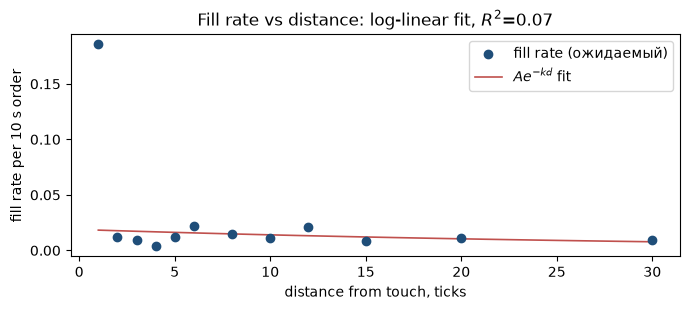

In [4]:
cal = fills.groupby('d').p.mean().reset_index()          # ожидаемый fill rate по расстоянию (без шума розыгрыша)
cal = cal[cal.p > 0]
slope, intercept, rv, pval, se = st.linregress(cal.d, np.log(cal.p))
k_hat = -slope; A_hat = np.exp(intercept); r2 = rv**2
print('все d:    A = %.3f, k = %.4f per tick, R² = %.3f (p=%.3g)' % (A_hat, k_hat, r2, pval))
c2 = cal[cal.d >= 2]
sl2, ic2, rv2, pv2, se2 = st.linregress(c2.d, np.log(c2.p))
print('только d>=2: k = %.4f per tick, R² = %.3f (p=%.2f)  <- без точки на touch зависимость от расстояния исчезает' % (-sl2, rv2**2, pv2))
print('fill rate:', {int(d): round(float(f), 4) for d, f in zip(cal.d, cal.p)})
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.scatter(cal.d, cal.p, color='#1f4e79', zorder=3, label='fill rate (ожидаемый)')
dd = np.linspace(1, max(DELTAS), 100)
ax.plot(dd, A_hat*np.exp(-k_hat*dd), color='#c0504d', lw=1.2, label=r'$A e^{-k d}$ fit')
ax.set_xlabel('distance from touch, ticks'); ax.set_ylabel('fill rate per 10 s order')
ax.set_title('Fill rate vs distance: log-linear fit, $R^2$=%.2f' % r2); ax.legend()
plt.tight_layout(); plt.show()

## Формулы: reservation price, ширина, γ и горизонт

Считаем два слагаемых полной ширины $\delta^a+\delta^b$ (в слайдах их называют «halves» теории, не полуширинами) и их отношение, но уже в согласованных единицах ($\sigma_{\text{шаг}}^2\cdot H$). $\gamma$ — предпочтение, а не параметр подгонки: значение со слайда $0.04$ показано как иллюстрация, а рабочее значение берётся из допуска по инвентарю — скью в 1 тик при $q=1$ BTC, $\gamma=\text{skew}/(q\,\sigma^2 H)$. Горизонт $T-t$ в круглосуточном рынке не задан: Время жизни инвентаря оценивается как $1/(2\lambda)$, где $\lambda$ — исполнения одной стороны на touch в секунду (единица инвентаря живёт до встречного исполнения). Ниже — чувствительность к $\gamma$ и к горизонту, оценка времени жизни инвентаря и сам reservation price для разных инвентарей. Ex-post ширина одной стороны $d$ тиков соответствует полной $1+2(d-1)$ тиков (touch плюс по $d-1$ с каждой стороны).

In [5]:
GAMMA = 0.04            # слайд 10 (иллюстрация); см. ниже — γ имеет единицы «1/(инвентарь × дисперсия)»
H = H_STEPS             # горизонт в шагах по 100 мс
sig_all = float(np.nanmean(sig))
struct_half = (2/GAMMA)*np.log(1 + GAMMA/k_hat)          # слагаемое market-structure полной ширины δa+δb
inv_half = GAMMA * sig_all**2 * H                        # слагаемое inventory-risk полной ширины: σ² — на шаг, H — число шагов
width_model = struct_half + inv_half
ratio = struct_half / inv_half
print('σ на шаг = %.2f тиков, горизонт H = %d шагов (10 с)' % (sig_all, H))
print('market-structure слагаемое (2/γ)ln(1+γ/k) = %.1f ticks' % struct_half)
print('inventory-risk слагаемое  γσ²H              = %.1f ticks' % inv_half)
print('полная ширина δa+δb                          = %.1f ticks' % width_model)
print('отношение structure/inventory = %.2fx  (в прежней версии σ² не умножалась на H: получалось 10.7x)' % ratio)

# γ ИЗ ДОПУСКА ПО ИНВЕНТАРЮ (слайд 22: γ — предпочтение, не параметр подгонки): хотим скью в 1 тик при q_max = 1 BTC
Q_MAX, SKEW_TARGET = 1.0, 1.0
GAMMA_TOL = SKEW_TARGET / (Q_MAX * sig_all**2 * H)
GAMMAS = {'γ=0.04 (слайд)': GAMMA, 'γ из допуска (скью 1 тик при q=1 BTC)': GAMMA_TOL}
rows = []
for gname, g in GAMMAS.items():
    sh = (2/g)*np.log(1 + g/k_hat); ih = g * sig_all**2 * H
    rows.append({'γ': gname, 'значение γ': g, 'structure': sh, 'inventory-risk': ih, 'full width': sh + ih, 'structure/inventory': sh/ih})
print('\nчувствительность к выбору γ:'); display(pd.DataFrame(rows).round(4))

# чувствительность к горизонту H (T−t): 1 с, 4.4 с (~время жизни инвентаря в лекции 12.10), 10 с, 60 с
rows = []
for Hh, lab in ((10, '1 с'), (44, '4.4 с'), (100, '10 с'), (600, '60 с')):
    for gname, g in GAMMAS.items():
        sh = (2/g)*np.log(1 + g/k_hat); ih = g * sig_all**2 * Hh
        rows.append({'горизонт': lab, 'γ': gname.split(' (')[0], 'inventory-risk': ih, 'full width': sh + ih, 'structure/inventory': sh/ih})
print('\nчувствительность к горизонту T−t:'); display(pd.DataFrame(rows).round(2))

# обоснование горизонта: время жизни инвентаря (горизонт — время жизни инвентаря, 1/(2λ))
touch_rate_10s = float(cal.loc[cal.d == 1, 'p'].iloc[0])          # вероятность исполнения стороны на touch за 10 с
lam_side = touch_rate_10s / 10.0                                  # исполнений на сторону в секунду
LIFE_S = 1.0 / (2 * lam_side)                                     # единица инвентаря живёт до встречного исполнения: 1/(λ_bid+λ_ask)
H_LIFE = int(round(LIFE_S * 10))                                  # в шагах по 100 мс
print('\nвремя жизни инвентаря при котировке на touch: λ на сторону = %.4f 1/с -> 1/(2λ) = %.0f с = %d шагов (в расчёте H = %d = 10 с)' % (lam_side, LIFE_S, H_LIFE, H))
rows = []
for gname, g in GAMMAS.items():
    for Hh, lab in ((H, '10 с (принято)'), (H_LIFE, '%.0f с (время жизни инвентаря)' % LIFE_S)):
        sh = (2/g)*np.log(1 + g/k_hat); ih = g * sig_all**2 * Hh
        rows.append({'γ': gname.split(' (')[0], 'горизонт': lab, 'inventory-risk': ih, 'full width': sh + ih, 'structure/inventory': sh/ih})
display(pd.DataFrame(rows).round(2))
print('горизонт 10 с — порядок величины времени жизни инвентаря; вывод о знаке ошибки от выбора между ними не зависит (см. чувствительность выше)')

# reservation price: r = s − q·γ·σ²·H  (скью = −q·γ·σ²·H), в тиках
def reservation(s, q, sig_t, gamma, Hh): return s - q * gamma * sig_t**2 * Hh * tick
mid0 = float(np.nanmean(mid))
rows = []
for q in (-2, -1, 0, 1, 2):
    rows.append({'q, BTC': q,
                 'скью γ=0.04, тиков': -q*GAMMA*sig_all**2*H,
                 'скью γ из допуска, тиков': -q*GAMMA_TOL*sig_all**2*H,
                 'r (γ из допуска), $': reservation(mid0, q, sig_all, GAMMA_TOL, H)})
print('\nreservation price и скью по инвентарю (mid = %.1f, спред = 1 тик):' % mid0); display(pd.DataFrame(rows).round(3))
print('при γ=0.04 один BTC сдвигает котировки на сотни тиков: единицы γ обратны «инвентарь × дисперсия», поэтому γ задаётся допуском по инвентарю, а не числом из примера')

σ на шаг = 11.05 тиков, горизонт H = 100 шагов (10 с)
market-structure слагаемое (2/γ)ln(1+γ/k) = 42.9 ticks
inventory-risk слагаемое  γσ²H              = 488.0 ticks
полная ширина δa+δb                          = 530.9 ticks
отношение structure/inventory = 0.09x  (в прежней версии σ² не умножалась на H: получалось 10.7x)

чувствительность к выбору γ:


,γ,значение γ,structure,inventory-risk,full width,structure/inventory
0,γ=0.04 (слайд),0.0400,42.8929,488.0314,530.9244,0.0879
1,γ из допуска (скью 1 тик при q=1 BTC),0.0001,67.8110,1.0000,68.8110,67.8110



чувствительность к горизонту T−t:


,горизонт,γ,inventory-risk,full width,structure/inventory
0,1 с,γ=0.04,48.80,91.70,0.88
1,1 с,γ из допуска,0.10,67.91,678.11
2,4.4 с,γ=0.04,214.73,257.63,0.20
3,4.4 с,γ из допуска,0.44,68.25,154.12
4,10 с,γ=0.04,488.03,530.92,0.09
5,10 с,γ из допуска,1.00,68.81,67.81
6,60 с,γ=0.04,2928.19,2971.08,0.01
7,60 с,γ из допуска,6.00,73.81,11.30



время жизни инвентаря при котировке на touch: λ на сторону = 0.0185 1/с -> 1/(2λ) = 27 с = 270 шагов (в расчёте H = 100 = 10 с)


,γ,горизонт,inventory-risk,full width,structure/inventory
0,γ=0.04,10 с (принято),488.03,530.92,0.09
1,γ=0.04,27 с (время жизни инвентаря),1317.68,1360.58,0.03
2,γ из допуска,10 с (принято),1.00,68.81,67.81
3,γ из допуска,27 с (время жизни инвентаря),2.70,70.51,25.12


горизонт 10 с — порядок величины времени жизни инвентаря; вывод о знаке ошибки от выбора между ними не зависит (см. чувствительность выше)

reservation price и скью по инвентарю (mid = 58501.1, спред = 1 тик):


,"q, BTC","скью γ=0.04, тиков","скью γ из допуска, тиков","r (γ из допуска), $"
0,-2,976.063,2.0,58501.289
1,-1,488.031,1.0,58501.189
2,0,0.000,0.0,58501.089
3,1,-488.031,-1.0,58500.989
4,2,-976.063,-2.0,58500.889


при γ=0.04 один BTC сдвигает котировки на сотни тиков: единицы γ обратны «инвентарь × дисперсия», поэтому γ задаётся допуском по инвентарю, а не числом из примера


## Ex-post profitable width и сравнение по режимам

Для каждого режима и $d$ считаем средний net на ордер: fill rate × (средний markout − fee). Ширина, максимизирующая это число среди ячеек с хотя бы одним **ожидаемым** исполнением ($\sum p\ge1$), — ex-post прибыльная ширина одной стороны; переводим её в полную ширину $1+2(d-1)$ и сравниваем с полной шириной модели. Знак ошибки — model − optimal. Неопределённость — блочный бутстрап по **окнам постановки** (ресэмплируются окна, а не отдельные ордера); для каждой ширины модели печатается доля ресэмплов, где ex-post оптимум не ниже модели. Дополнительно: чувствительность оптимума к комиссии (0–2 bp) и проверка вне выборки — $A,k$ из первой половины окна, ex-post оптимум из второй.

In [6]:
MINP = 1.0       # минимум ожидаемых филлов в ячейке, чтобы считать её оптимумом
okc = by[by.eff_fills >= MINP]
opt = okc.loc[okc.groupby('reg').net_per_order.idxmax()].copy()
opt['reg_name'] = opt.reg.map(names)
opt['opt_full'] = 1 + 2*(opt.d - 1)
print('ex-post optimal width (ячейки с Σp >= %.0f):' % MINP)
display(opt[['reg_name', 'd', 'opt_full', 'fill', 'eff_fills', 'mark', 'net_per_order']].round(3))

# блочный бутстрап по окнам: ресэмплируем окна постановки, а не отдельные ордера
MATS = {}
for r in range(3):
    f = fills[fills.reg == r]
    P = f.pivot_table(index='w', columns='d', values='p', aggfunc='sum')
    PM = f.assign(pm=f.p*f.mark_if).pivot_table(index='w', columns='d', values='pm', aggfunc='sum')
    C = f.pivot_table(index='w', columns='d', values='p', aggfunc='size')
    MATS[r] = (P.values, PM.values, C.values, list(P.columns))

def boot_opt(r, n_boot=500, seed=1):
    P, PM, C, cols = MATS[r]
    rng = np.random.default_rng(seed); out = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(P), len(P))
        p, pm, c = P[idx].sum(0), PM[idx].sum(0), C[idx].sum(0)
        mk = np.where(p > 0, pm / np.where(p > 0, p, 1), 0.0)
        net = np.where(p >= MINP, (p/c) * (mk - FEE), -np.inf)
        out.append(cols[int(np.argmax(net))])
    return np.array(out)

sig_reg = fills.groupby('reg').sigma.mean()
BOOT = {r: boot_opt(r) for r in range(3)}
rows = []
for r in range(3):
    opt_full = float(opt.loc[opt.reg == r, 'opt_full'].iloc[0])
    bo_full = 1 + 2*(BOOT[r] - 1)
    row = {'regime': names[r], 'σ шага': round(float(sig_reg[r]), 2), 'optimal full': opt_full,
           'optimal full 5–95%': '%d–%d' % (np.quantile(bo_full, .05), np.quantile(bo_full, .95))}
    for gname, g in GAMMAS.items():
        sh = (2/g)*np.log(1 + g/k_hat)
        wc = g * sig_all**2 * H + sh
        wd = g * sig_reg[r]**2 * H + sh
        tag = 'γ=0.04' if g == GAMMA else 'γ_tol'
        row['model const %s' % tag] = round(wc, 1); row['error const %s' % tag] = round(wc - opt_full, 1)
        row['model dyn %s' % tag] = round(wd, 1)
        row['P(opt >= model const) %s' % tag] = round(float(np.mean(bo_full >= wc)), 3)
    rows.append(row)
cmp = pd.DataFrame(rows)
print('\nmodel vs ex-post optimal (full width, тиков):')
display(cmp.T)
for r in range(3):
    vals, cnt = np.unique(BOOT[r], return_counts=True)
    top = sorted(zip(cnt, vals), reverse=True)[:3]
    print('%s: bootstrap argmax d top=%s, 5–95%% range d=%d–%d ticks (полная ширина %d–%d)' % (
        names[r], [(int(v), int(c)) for c, v in top], np.quantile(BOOT[r], .05), np.quantile(BOOT[r], .95),
        1 + 2*(np.quantile(BOOT[r], .05) - 1), 1 + 2*(np.quantile(BOOT[r], .95) - 1)))

# чувствительность к комиссии: от 0 до 2 bp (2 bp — Bybit VIP0 maker, cited в hw14: https://www.bybit.com/en/help-center/article/Trading-Fee-Structure, доступ 2026-10-20)
mid_all = float(np.nanmean(mid))
rows = []
for fee_bp in (0.0, 0.1, 0.5, 1.0, 2.0):
    fee_t = fee_bp * 1e-4 * mid_all / tick
    row = {'fee, bp': fee_bp, 'fee, тиков': round(fee_t, 2)}
    for r in range(3):
        c = by[(by.reg == r) & (by.eff_fills >= MINP)].copy()
        c['net'] = c.fill * (c.mark - fee_t)
        b = c.loc[c.net.idxmax()]
        row[names[r]] = 'd=%d (полная %d), net %+.2f' % (b.d, 1 + 2*(b.d - 1), b.net)
    rows.append(row)
print('\nex-post оптимум при разной комиссии:'); display(pd.DataFrame(rows))

# калибровка на первой половине, проверка на второй: k и оптимум не подглядывают в проверяемую половину
half_w = fills.w.median()
f1, f2 = fills[fills.w < half_w], fills[fills.w >= half_w]
c1 = f1.groupby('d').p.mean().reset_index(); c1 = c1[c1.p > 0]
sl1, ic1, rr1, pv1, se1 = st.linregress(c1.d, np.log(c1.p))
k1 = -sl1
g2 = agg_cells(f2); g2o = g2[g2.eff_fills >= 0.5]
rows = []
for r in range(3):
    c = g2o[g2o.reg == r]
    b = c.loc[c.net_per_order.idxmax()]
    wd = GAMMA_TOL * float(f2[f2.reg == r].sigma.mean())**2 * H + (2/GAMMA_TOL)*np.log(1 + GAMMA_TOL/k1)
    rows.append({'regime': names[r], 'k (1-я половина)': round(k1, 4), 'optimal full (2-я половина)': 1 + 2*(b.d - 1),
                 'model (γ_tol, k из 1-й половины)': round(wd, 1), 'error': round(wd - (1 + 2*(b.d - 1)), 1)})
print('\nвне выборки: A,k из первой половины окна, ex-post оптимум из второй (Σp >= 0.5 в ячейке):'); display(pd.DataFrame(rows))

ex-post optimal width (ячейки с Σp >= 1):


,reg_name,d,opt_full,fill,eff_fills,mark,net_per_order
5,calm,6,11,0.023,3.045,38.209,0.758
18,normal,8,15,0.015,1.508,-16.888,-0.336
32,stress,12,23,0.011,1.201,181.716,1.956



model vs ex-post optimal (full width, тиков):


,0,1,2
regime,calm,normal,stress
σ шага,5.6,10.7,18.44
optimal full,11.0,15.0,23.0
optimal full 5–95%,11–39,9–59,1–29
model const γ=0.04,530.9,530.9,530.9
error const γ=0.04,519.9,515.9,507.9
model dyn γ=0.04,168.1,501.0,1402.8
P(opt >= model const) γ=0.04,0.0,0.0,0.0
model const γ_tol,68.8,68.8,68.8
error const γ_tol,57.8,53.8,45.8


calm: bootstrap argmax d top=[(6, 220), (12, 210), (30, 20)], 5–95% range d=6–20 ticks (полная ширина 11–39)
normal: bootstrap argmax d top=[(6, 192), (8, 153), (30, 70)], 5–95% range d=5–30 ticks (полная ширина 9–59)
stress: bootstrap argmax d top=[(12, 265), (5, 89), (15, 54)], 5–95% range d=1–15 ticks (полная ширина 1–29)

ex-post оптимум при разной комиссии:


,"fee, bp","fee, тиков",calm,normal,stress
0,0.0,0.00,"d=6 (полная 11), net +0.90","d=8 (полная 15), net -0.25","d=12 (полная 23), net +2.02"
1,0.1,5.85,"d=6 (полная 11), net +0.76","d=8 (полная 15), net -0.34","d=12 (полная 23), net +1.96"
2,0.5,29.25,"d=6 (полная 11), net +0.21","d=8 (полная 15), net -0.68","d=12 (полная 23), net +1.70"
3,1.0,58.50,"d=15 (полная 29), net -0.36","d=30 (полная 59), net -1.11","d=12 (полная 23), net +1.37"
4,2.0,117.00,"d=15 (полная 29), net -0.87","d=30 (полная 59), net -1.83","d=12 (полная 23), net +0.72"



вне выборки: A,k из первой половины окна, ex-post оптимум из второй (Σp >= 0.5 в ячейке):


,regime,k (1-я половина),optimal full (2-я половина),"model (γ_tol, k из 1-й половины)",error
0,calm,0.033,23.0,60.8,37.8
1,normal,0.033,3.0,61.4,58.4
2,stress,0.033,1.0,63.0,62.0


## Dynamic terms: conditional σ и adverse selection

Два динамических члена: (1) $\sigma_t$ на коротком окне вместо константы; (2) adverse-selection term из markout'ов на touch. Adverse selection оценивается по ожидаемым исполнениям (не по разыгранным), с 90%-м блочным бутстрап-интервалом. По слайду 18 член входит в полуширину, поэтому к полной ширине добавляется $2\cdot\text{adv}$. Оба члена — измеряемые величины, не веса, подогнанные по P&L; тестируем каждый отдельно и вместе, смотрим marginal effect.

In [7]:
# adverse selection на touch: markout, взвешенный по вероятности филла, с блочным бутстрапом по окнам
j1 = MATS[0][3].index(1)
adv_rows, ADV = [], {}
for r in range(3):
    P, PM, C, cols = MATS[r]
    p = P[:, j1].sum(); m = PM[:, j1].sum() / p
    rng = np.random.default_rng(2); bs = []
    for _ in range(500):
        idx = rng.integers(0, len(P), len(P))
        pp = P[idx, j1].sum(); bs.append(PM[idx, j1].sum() / pp if pp > 0 else np.nan)
    lo, hi = np.nanquantile(bs, [.05, .95])
    ADV[r] = -m
    adv_rows.append({'regime': names[r], 'ожидаемых филлов на touch': round(p, 1), 'markout, тики': round(m, 1), '5–95%': '%.0f … %.0f' % (lo, hi), 'adverse selection = −markout': round(-m, 1)})
print('adverse selection на touch (ожидаемые исполнения, блочный бутстрап 90%):')
display(pd.DataFrame(adv_rows))

dyn = []
for r in range(3):
    opt_full = float(opt.loc[opt.reg == r, 'opt_full'].iloc[0])
    base = GAMMA * sig_all**2 * H + struct_half
    cond = GAMMA * sig_reg[r]**2 * H + struct_half
    base_adv = base + 2 * float(ADV[r])           # слайд 18: half_width += adverse_selection → полная ширина +2·adv
    both = cond + 2 * float(ADV[r])
    dyn.append({'regime': names[r], 'optimal full': opt_full, 'base': round(base, 1), 'conditional sigma': round(cond, 1),
                'base+adv': round(base_adv, 1), 'both': round(both, 1),
                'marginal sigma': round(cond - base, 1), 'marginal adv': round(base_adv - base, 1)})
print('\ndynamic terms (γ=0.04, полная ширина, тики):'); display(pd.DataFrame(dyn))

adverse selection на touch (ожидаемые исполнения, блочный бутстрап 90%):


,regime,ожидаемых филлов на touch,"markout, тики",5–95%,adverse selection = −markout
0,calm,27.0,-26.1,-43 … -8,26.1
1,normal,15.8,-71.8,-104 … -41,71.8
2,stress,20.3,-22.1,-87 … 30,22.1



dynamic terms (γ=0.04, полная ширина, тики):


,regime,optimal full,base,conditional sigma,base+adv,both,marginal sigma,marginal adv
0,calm,11.0,530.9,168.1,583.0,220.2,-362.8,52.1
1,normal,15.0,530.9,501.0,674.6,644.7,-29.9,143.7
2,stress,23.0,530.9,1402.8,575.2,1447.0,871.8,44.2


## Чувствительность k к горизонту

$k$ — не свойство рынка, а функция выбранного горизонта: чем дольше живёт котировка, тем больше дальних филлов и тем меньше $k$. Проверяем время жизни заявки 10/50/100 секунд (шаг постановки 10 с, окна перекрываются, поэтому точки не независимы): если вывод «модель шире ex-post оптимума» держится при всех, он не зависит от произвольно выбранного горизонта.

In [8]:
sweep = []
for life in [100, 500, 1000]:
    f = build_fill_log(lifetime=life, step=100)
    c = f.groupby('d').p.mean().reset_index()
    c = c[c.p > 0]
    if len(c) >= 3:
        sl, ic, rr_, pv, se_ = st.linregress(c.d, np.log(c.p))
        kk = -sl; st_half = (2/GAMMA)*np.log(1 + GAMMA/kk) if kk > 0 else np.nan
        r2s = rr_**2
    else:
        kk, r2s, st_half = np.nan, np.nan, np.nan
    sweep.append({'lifetime_s': life/10, 'k': round(kk, 4), 'R2': round(r2s, 3),
                  'struct': round(st_half, 2) if np.isfinite(st_half) else np.nan,
                  'width (γ=0.04, H=lifetime)': round(st_half + GAMMA*sig_all**2*life, 2) if np.isfinite(st_half) else np.nan})
display(pd.DataFrame(sweep))

,lifetime_s,k,R2,struct,"width (γ=0.04, H=lifetime)"
0,10.0,0.0295,0.073,42.89,530.92
1,50.0,0.0175,0.066,59.52,2499.68
2,100.0,0.0119,0.046,73.75,4954.06


## Те же выводы на больших окнах

В 30-минутном окне ожидаемых исполнений мало (63 на touch, 1–3 на ячейку при $d\ge2$), поэтому тот же анализ повторён на 4 часах (12:00–16:00) и на всех двух сутках данных (01–03.07, 402 тыс. гипотетических ордеров, около 6.6 тыс. ожидаемых исполнений на touch). Режимы — expanding-терцили σ внутри каждого окна; для ex-post оптимума берутся ячейки с достаточным числом ожидаемых исполнений (1, 20 и 50). γ из допуска пересчитывается по σ окна.

In [9]:
# Тот же анализ на больших окнах: 4 часа и двое суток. В 30-минутном окне ожидаемых исполнений слишком мало.
def load_window(T0_, T1_):
    pn = con.execute(f"""SELECT event_time, mid, best_bid, best_ask, best_bid_amount, best_ask_amount
        FROM read_parquet('{Q}') WHERE asset='BTC' AND exchange='Bybit'
        AND event_time >= TIMESTAMPTZ '{T0_}' AND event_time < TIMESTAMPTZ '{T1_}' ORDER BY event_time""").df().reset_index(drop=True)
    tr_ = con.execute(f"""SELECT event_time, price, amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
        WHERE symbol='BTCUSDT' AND event_time >= TIMESTAMPTZ '{T0_}' AND event_time < TIMESTAMPTZ '{T1_}' ORDER BY event_time""").df()
    n_ = len(pn); mid_ = pn.mid.values
    ib_ = np.searchsorted(to_ns(pn.event_time), to_ns(tr_.event_time), side='right') - 1
    ok_ = (ib_ >= 0) & (ib_ < n_)
    ret_ = np.diff(mid_, prepend=mid_[0])
    sg = pd.Series(ret_).rolling(100).std().values / tick
    s_ = pd.Series(sg)
    a1 = s_.expanding(min_periods=600).quantile(1/3).values; a2 = s_.expanding(min_periods=600).quantile(2/3).values
    rg = np.where(sg <= a1, 0, np.where(sg <= a2, 1, 2)); rg = np.where(np.isnan(a1), 1, rg)
    return dict(n=n_, mid=mid_, bb=pn.best_bid.values, ba=pn.best_ask.values, bba=pn.best_bid_amount.values, baa=pn.best_ask_amount.values,
                ib=ib_[ok_], tp=tr_.price.to_numpy()[ok_], ta=tr_.amount.to_numpy()[ok_], sig=sg, reg=rg)

def analyze_window(ctx, minp, n_boot=300):
    f = build_fill_log(100, 100, ctx=ctx)
    sg = float(np.nanmean(ctx['sig']))
    fee_t = 0.1e-4 * float(np.nanmean(ctx['mid'])) / tick
    cl = f.groupby('d').p.mean().reset_index(); cl = cl[cl.p > 0]
    s_a, i_a, r_a, p_a, _ = st.linregress(cl.d, np.log(cl.p))
    c_2 = cl[cl.d >= 2]; s_2, i_2, r_2, p_2, _ = st.linregress(c_2.d, np.log(c_2.p))
    k_ = -s_a
    g_tol = SKEW_TARGET / (Q_MAX * sg**2 * H)
    out = {'ордеров': len(f), 'Σp на touch': round(float(f[f.d == 1].p.sum()), 0), 'k (все d)': round(k_, 4), 'R²': round(r_a**2, 3),
           'k (d>=2)': round(-s_2, 4), 'σ шага': round(sg, 2)}
    for tag, g in (('γ=0.04', GAMMA), ('γ_tol', g_tol)):
        out['width %s' % tag] = round((2/g)*np.log(1 + g/k_) + g * sg**2 * H, 1)
        out['structure/inventory %s' % tag] = round(((2/g)*np.log(1 + g/k_)) / (g * sg**2 * H), 2)
    cells_ = agg_cells(f)
    cells_['net_per_order'] = cells_.fill * (cells_.mark - fee_t)
    okc_ = cells_[cells_.eff_fills >= minp]
    for r in range(3):
        sub = okc_[okc_.reg == r]
        b = sub.loc[sub.net_per_order.idxmax()]
        of = 1 + 2*(b.d - 1)
        fr = f[f.reg == r]
        P = fr.pivot_table(index='w', columns='d', values='p', aggfunc='sum').values
        PM = fr.assign(pm=fr.p*fr.mark_if).pivot_table(index='w', columns='d', values='pm', aggfunc='sum').values
        C = fr.pivot_table(index='w', columns='d', values='p', aggfunc='size').values
        rng_ = np.random.default_rng(1); bo = []
        for _ in range(n_boot):
            idx = rng_.integers(0, len(P), len(P))
            p_, pm_, c_ = P[idx].sum(0), PM[idx].sum(0), C[idx].sum(0)
            mk_ = np.where(p_ > 0, pm_ / np.where(p_ > 0, p_, 1), 0.0)
            net_ = np.where(p_ >= minp, (p_/c_) * (mk_ - fee_t), -np.inf)
            bo.append(DELTAS[int(np.argmax(net_))])
        bof = 1 + 2*(np.array(bo) - 1)
        out['%s: optimal full (net)' % names[r]] = '%d (%+.2f), 5–95%%: %d–%d' % (of, b.net_per_order, np.quantile(bof, .05), np.quantile(bof, .95))
        out['%s: error γ_tol' % names[r]] = round((2/g_tol)*np.log(1 + g_tol/k_) + g_tol * float(fr.sigma.mean())**2 * H - of, 1)
        out['%s: P(opt>=model γ_tol)' % names[r]] = round(float(np.mean(bof >= (2/g_tol)*np.log(1 + g_tol/k_) + g_tol * float(fr.sigma.mean())**2 * H)), 3)
    return out

WINDOWS = [('30 мин (основной)', T0, T1, 1.0), ('4 часа 12:00–16:00', '2026-07-01 12:00:00+00', '2026-07-01 16:00:00+00', 20.0),
           ('двое суток 01–03.07', '2026-07-01 00:00:00+00', '2026-07-03 00:00:00+00', 50.0)]
ROB = {}
for lab, a_, b_, mp in WINDOWS:
    ctx_ = load_window(a_, b_)
    ROB[lab] = analyze_window(ctx_, mp)
display(pd.DataFrame(ROB).T)
print('Минимум ожидаемых исполнений в ячейке для оптимума: 1 (30 мин), 20 (4 часа), 50 (двое суток). Режимы — expanding-терцили σ внутри каждого окна.')

,ордеров,Σp на touch,k (все d),R²,k (d>=2),σ шага,width γ=0.04,structure/inventory γ=0.04,width γ_tol,structure/inventory γ_tol,calm: optimal full (net),calm: error γ_tol,calm: P(opt>=model γ_tol),normal: optimal full (net),normal: error γ_tol,normal: P(opt>=model γ_tol),stress: optimal full (net),stress: error γ_tol,stress: P(opt>=model γ_tol)
30 мин (основной),4080,63.0,0.0295,0.073,-0.0009,11.05,530.9,0.09,68.8,67.81,"11 (+0.76), 5–95%: 5–29",57.1,0.0,"15 (-0.34), 5–95%: 9–59",53.7,0.0,"23 (+1.96), 5–95%: 1–29",47.6,0.0
4 часа 12:00–16:00,34128,619.0,0.035,0.177,0.0109,16.67,1150.0,0.03,58.1,57.12,"3 (-1.77), 5–95%: 1–5",54.3,0.0,"3 (-1.91), 5–95%: 3–59",54.8,0.083,"9 (-0.02), 5–95%: 3–59",50.3,0.0
двое суток 01–03.07,401856,6556.0,0.0301,0.106,0.0014,10.18,456.5,0.1,67.3,66.33,"7 (-0.36), 5–95%: 5–59",59.4,0.0,"11 (-0.35), 5–95%: 5–29",56.1,0.0,"9 (-0.47), 5–95%: 3–29",60.8,0.0


Минимум ожидаемых исполнений в ячейке для оптимума: 1 (30 мин), 20 (4 часа), 50 (двое суток). Режимы — expanding-терцили σ внутри каждого окна.


## Проверка на look-ahead

σ и режим считаются только по прошлому; котировка ставится в $t$, филлы ищутся в $[t,t+10s)$, markout — в $t+10s$ и используется только для оценки исхода. Проверим префикс-инвариантность σ и режима и границы окна филлов. Отдельно проверим устойчивость A и k по половинам окна: параметры, подогнанные по всей выборке и применённые в ней же, — ловушка слайда 22.

In [10]:
k = 5000
sig_pref = pd.Series(np.diff(mid[:k], prepend=mid[0])).rolling(100).std().values/tick
print('σ prefix identical:', np.allclose(sig[:k], sig_pref, equal_nan=True))
s_pref = pd.Series(sig_pref)
q1p = s_pref.expanding(min_periods=600).quantile(1/3).values; q2p = s_pref.expanding(min_periods=600).quantile(2/3).values
reg_pref = np.where(sig_pref <= q1p, 0, np.where(sig_pref <= q2p, 1, 2)); reg_pref = np.where(np.isnan(q1p), 1, reg_pref)
print('режим prefix-инвариантен (расширяющиеся терцили по прошлому):', bool(np.all(reg_pref == reg[:k])))
audit = []
for i in range(0, min(n-110, 5000), 100):
    j0 = np.searchsorted(ib, i, 'left'); j1_ = np.searchsorted(ib, i+100, 'left')
    if j1_ > j0: audit.append((i, int(ib[j0]), int(ib[j1_-1])))
bad = [a for a in audit if not (a[0] <= a[1] <= a[2] < a[0]+100)]
print('окон с трейдами:', len(audit), '| нарушений окна:', len(bad))
print('markout берёт mid[i+lifetime] только для оценки исхода; на решение (σ, режим, котировка) он не влияет.')
print('A и k подогнаны по всему окну и применяются в нём же (in-sample); слайд 22 требует скользящей оценки. Проверка устойчивости по половинам окна:')
half = fills.w.median()
HALF_K = {}
for nm, f in (('1-я половина (15 мин)', fills[fills.w < half]), ('2-я половина (15 мин)', fills[fills.w >= half])):
    c = f.groupby('d').p.mean().reset_index(); c = c[c.p > 0]
    sl_, ic_, rr_, pv_, se_ = st.linregress(c.d, np.log(c.p))
    HALF_K[nm] = -sl_
    print('  %s: k = %.4f, R² = %.3f, fill rate на touch %.3f, d>=2 в среднем %.4f' % (nm, -sl_, rr_**2, c.p.iloc[0], c.p.iloc[1:].mean()))

σ prefix identical: True
режим prefix-инвариантен (расширяющиеся терцили по прошлому): True
окон с трейдами: 50 | нарушений окна: 0
markout берёт mid[i+lifetime] только для оценки исхода; на решение (σ, режим, котировка) он не влияет.
A и k подогнаны по всему окну и применяются в нём же (in-sample); слайд 22 требует скользящей оценки. Проверка устойчивости по половинам окна:
  1-я половина (15 мин): k = 0.0330, R² = 0.091, fill rate на touch 0.218, d>=2 в среднем 0.0151
  2-я половина (15 мин): k = 0.0167, R² = 0.010, fill rate на touch 0.153, d>=2 в среднем 0.0096


## Сводка и честный вывод

Сводная таблица ниже собирает ответы на пункты лабораторной: калибровку, отношение двух слагаемых, сравнение по режимам (главный пункт), marginal effect динамических членов и чувствительность к горизонту.

In [11]:
summary = pd.DataFrame([
    {'что': 'A, k, R² (все d)', 'значение': '%.3f, %.4f, %.3f' % (A_hat, k_hat, r2)},
    {'что': 'k только по d>=2', 'значение': '%.4f (R²=%.3f)' % (-sl2, rv2**2)},
    {'что': 'σ на шаг, ticks; H = 100 шагов', 'значение': '%.2f' % sig_all},
    {'что': 'structure / inventory (γ=0.04)', 'значение': '%.1f / %.1f = %.2fx' % (struct_half, inv_half, ratio)},
    {'что': 'γ из допуска по инвентарю', 'значение': '%.2e' % GAMMA_TOL},
    {'что': 'ex-post optimal full width', 'значение': ', '.join('%s %.0f' % (names[r], opt.loc[opt.reg == r, 'opt_full'].iloc[0]) for r in range(3))},
    {'что': 'bootstrap 5–95% optimal full', 'значение': ', '.join('%s %s' % (names[r], cmp.loc[cmp.regime == names[r], 'optimal full 5–95%'].iloc[0]) for r in range(3))},
    {'что': 'error const (γ=0.04) by regime', 'значение': ', '.join('%s %+.0f' % (names[r], cmp.loc[cmp.regime == names[r], 'error const γ=0.04'].iloc[0]) for r in range(3))},
    {'что': 'error const (γ из допуска) by regime', 'значение': ', '.join('%s %+.0f' % (names[r], cmp.loc[cmp.regime == names[r], 'error const γ_tol'].iloc[0]) for r in range(3))},
    {'что': 'k vs горизонт', 'значение': ', '.join('%s s k=%.3f' % (x['lifetime_s'], x['k']) for x in sweep)},
])
display(summary)

,что,значение
0,"A, k, R² (все d)","0.019, 0.0295, 0.073"
1,k только по d>=2,-0.0009 (R²=0.000)
2,"σ на шаг, ticks; H = 100 шагов",11.05
3,structure / inventory (γ=0.04),42.9 / 488.0 = 0.09x
4,γ из допуска по инвентарю,8.20e-05
5,ex-post optimal full width,"calm 11, normal 15, stress 23"
6,bootstrap 5–95% optimal full,"calm 11–39, normal 9–59, stress 1–29"
7,error const (γ=0.04) by regime,"calm +520, normal +516, stress +508"
8,error const (γ из допуска) by regime,"calm +58, normal +54, stress +46"
9,k vs горизонт,"10.0 s k=0.029, 50.0 s k=0.018, 100.0 s k=0.012"


## Вывод

На BTC-USDT Bybit модель **не проходит** сравнение по режимам, и ошибка **не меняет знак**: модель шире ex-post оптимума во всех режимах.

- **Калибровка.** $A=0.019$, $k=0.0295$ за тик, $R^2=0.073$ (p≈0.40). Fill rate на touch $0.19$, а при $d\ge2$ почти плоский ($\approx0.01$) без зависимости от расстояния: фит только по $d\ge2$ даёт $k\approx0$, $R^2=0$. Значение $k$ держится на одной точке $d=1$, по половинам окна оно нестабильно ($0.033$ и $0.017$), с горизонтом падает ($0.029\to0.018\to0.012$ при 10/50/100 с). Форма $Ae^{-k\delta}$ инструмент не описывает; всё, что зависит от $k$ (market-structure слагаемое), — оценка низкого качества.
- **Единицы и отношение слагаемых.** σ на шаг 100 мс $=11.05$ тика, горизонт $H=100$ шагов. При $\gamma=0.04$ (слайд) inventory-risk слагаемое $=488$ тиков, market-structure $=43$, полная ширина $531$; отношение structure/inventory $=0.09\times$, то есть доминирует инвентарный риск (в прежней версии σ² не умножалась на $H$ и выходило $10.7\times$ с обратным выводом). При $\gamma$ из допуска по инвентарю ($8.2\cdot10^{-5}$: скью в 1 тик при 1 BTC) inventory-слагаемое $=1$ тик, structure $=68$, полная ширина $69$, отношение $68\times$. Вывод «какая половина теории важна» целиком определяется выбором $\gamma$ (и горизонта), поэтому он не свойство инструмента.
- **Reservation price.** При $\gamma=0.04$ один BTC инвентаря сдвигает котировки на $\pm488$ тиков — бессмысленно на инструменте со спредом в один тик; при $\gamma$ из допуска скью $=1$ тик на 1 BTC, то есть на одной ценовой сетке рекомендация модели — сдвиг на один тик, и выражать её надо размером и очередью, а не ценой.
- **Ex-post прибыльная ширина** (полная): calm $11$, normal $15$, stress $23$ тика, 90%-интервал блочного бутстрапа $11–39$ / $9–59$ / $1–29$. Опираются они на 1–3 ожидаемых исполнения на ячейку, поэтому интервалы широкие; в normal все ячейки имеют отрицательный net (после комиссии 5.85 тика) — прибыльной ширины нет, «оптимум» там означает «наименее убыточная ячейка». Ошибка модели: при $\gamma=0.04$ $+520/+516/+508$ тиков, при $\gamma$ из допуска $+58/+54/+46$; доля бутстрап-ресэмплов, где оптимум не ниже модели, $=0$ во всех режимах при обоих $\gamma$.
- **Динамические члены.** Условная σ при $\gamma=0.04$ меняет ширину на $-363/-30/+872$ тиков (calm/normal/stress): знак правильный (уже в спокойном, шире в стрессе), но величины огромны из-за квадрата σ; при $\gamma$ из допуска эффект $\approx0$. Adverse selection на touch по ожидаемым исполнениям (27/16/20): markout $-26/-72/-22$ тика, 90%-интервалы $[-43,-8]$, $[-104,-41]$, $[-87,+30]$: в stress интервал включает ноль, различия между режимами статистически слабые. Ни один из членов не делает ошибку отрицательной.
- **Комиссия и вне выборки.** При комиссии 0 bp в normal прибыльной ширины всё равно нет (net $-0.25$), при $\ge1$ bp перестают быть прибыльными и calm, и normal (net $-0.36$ и $-1.11$); в stress оптимум $d=12$ остаётся положительным и при 2 bp, но держится на одном крупном markout ($+182$ тика), поэтому ему доверять нельзя. Калибровка по первой половине окна и ex-post оптимум по второй дают ошибку модели $+38/+58/+62$ тиков (γ из допуска): знак тот же, что in-sample.
- **Горизонт.** Чем длиннее жизнь заявки, тем меньше $k$ и тем шире модель ($\gamma=0.04$: полная ширина растёт вместе с $H$ квадратично через σ²H), то есть вывод «модель шире оптимума» усиливается, а не зависит от выбранных 10 секунд. Оценка времени жизни инвентаря при котировке на touch $1/(2\lambda)\approx27$ с (270 шагов): принятые 10 секунд — того же порядка, при 27 с inventory-слагаемое растёт в 2.7 раза ($\gamma=0.04$: 1318 тиков; $\gamma$ из допуска: 2.7 тика), вывод о знаке ошибки не меняется.
- **Короткие окна (96 последовательных 30-минутных окон, конец ноутбука).** Знак ошибки положителен в **288 из 288** случаев «окно × режим» (медиана $+52$ тика, 10–90%: $+28…+64$), медиана оптимальной полной ширины $15$ тиков (10–90%: $3…39$), в ячейке оптимума в среднем всего $1.6$ ожидаемых исполнения. Net выбранного оптимума положителен в $71\%$ окон и в среднем $+1.22$ тика на ордер in-sample, но у той же ширины в следующем окне он $-1.01$: максимум по 12 шумным ячейкам, выбранный и оценённый на одних данных (winner's curse). Поэтому точные 30-минутные ширины 11/15/23 доверия не заслуживают, а устойчив только вывод «модель шире оптимума».

**Что это значит.** Структура модели полезна (скью с инвентарём, два независимых слагаемых), но как quoting policy на этом инструменте её использовать нельзя: спред в один тик, плоская кривая филлов за пределами touch, σ с тяжёлыми хвостами (5.8% шагов с $|\Delta\text{mid}|>20$ тиков), и без queue-aware интенсивности ширина определяется артефактом калибровки. Ожидаемый «сильный проход» из слайдов — ошибка, меняющая знак по режимам, — **не воспроизводится**; слайд 16 допускает такой исход, если режимы узки. Ограничения: A и k подогнаны по всему 30-минутному окну (in-sample), в ожидаемых исполнениях по ячейкам мало данных, комиссия 0.1 bp — допущение, контрфактический fill-лог построен по публичной ленте, а не по своим исполнениям.

## Короткие окна: двое суток, нарезанные на 96 последовательных 30-минутных окон

Большие окна смешивают разные состояния рынка, а оптимум по 12 шумным ячейкам одного 30-минутного окна страдает от winner's curse (максимум выбирается и оценивается на одних данных). Поэтому здесь для **каждого** 30-минутного окна отдельно (те же режимы по expanding-терцилям σ внутри окна, те же $d$, комиссия 0.1 bp) считается ex-post оптимальная полная ширина и ошибка модели (γ из допуска, $k$ с двух суток) $=$ модель $-$ оптимум. Ячейки с $\sum p<1$ оптимумом не считаются. Дальше — доля окон с положительной ошибкой, разброс оптимума, доля окон, где net оптимума положителен, и сравнение net выбранной ширины in-sample с её net в следующем окне.

окон: 96 из 96; (окно × режим) без ячейки с Σp>=1: 0 из 288


,режим,окон,доля error>0,"error, медиана","error, 10–90%","optimal full, медиана","optimal full, 10–90%",доля окон с net оптимума > 0,"Σp в ячейке оптимума, медиана",net оптимума in-sample,net того же d в след. окне
0,calm,96,1.0,51.8,28…64,15.0,3…39,0.667,1.6,0.63,-0.62
1,normal,96,1.0,52.2,28…62,15.0,5…39,0.688,1.7,0.97,-0.95
2,stress,96,1.0,53.7,8…64,13.0,3…59,0.771,1.8,2.07,-1.55
3,все,288,1.0,52.3,28…64,15.0,3…39,0.708,1.6,1.22,-1.01


«net оптимума in-sample» — максимум по ячейкам, выбранный и оценённый на тех же данных; «в след. окне» — оценка той же ширины на новых данных. Разница — winner's curse.


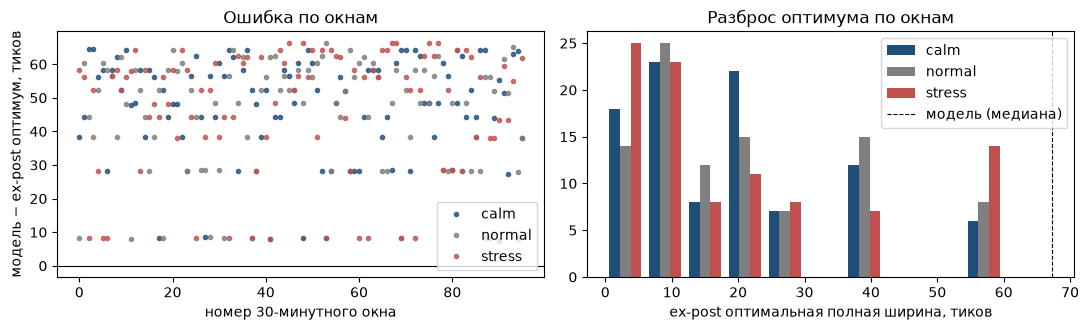

In [12]:
# Двое суток, нарезанные на 96 последовательных 30-минутных окон: держится ли знак ошибки в коротких окнах и насколько они шумят
K_GLOB = ROB['двое суток 01–03.07']['k (все d)']             # k с двух суток: общая калибровка, чтобы сравнивать окна по оптимуму
starts = pd.date_range('2026-07-01 00:00:00+00:00', '2026-07-02 23:30:00+00:00', freq='30min')
rows_w, CELLS_W = [], {}
for wi, a in enumerate(starts):
    b = a + pd.Timedelta(minutes=30)
    ctx_ = load_window(a.strftime('%Y-%m-%d %H:%M:%S+00'), b.strftime('%Y-%m-%d %H:%M:%S+00'))
    if ctx_['n'] < 5000: continue
    f_ = build_fill_log(100, 100, ctx=ctx_)
    sg_ = float(np.nanmean(ctx_['sig'])); g_ = SKEW_TARGET / (Q_MAX * sg_**2 * H)
    fee_ = 0.1e-4 * float(np.nanmean(ctx_['mid'])) / tick
    cl_ = agg_cells(f_); cl_['net'] = cl_.fill * (cl_.mark - fee_)
    CELLS_W[wi] = cl_
    model_ = (2/g_)*np.log(1 + g_/K_GLOB) + g_ * sg_**2 * H
    for r in range(3):
        sub = cl_[(cl_.reg == r) & (cl_.eff_fills >= 1.0)]            # ячейки с Σp < 1 оптимумом не считаются
        if len(sub) == 0:
            rows_w.append({'w': wi, 'regime': names[r], 'opt_full': np.nan, 'opt_net': np.nan, 'eff': np.nan, 'd': np.nan, 'model': model_, 'error': np.nan})
            continue
        bb_ = sub.loc[sub.net.idxmax()]
        rows_w.append({'w': wi, 'regime': names[r], 'opt_full': 1 + 2*(bb_.d - 1), 'opt_net': bb_.net, 'eff': bb_.eff_fills, 'd': bb_.d,
                       'model': model_, 'error': model_ - (1 + 2*(bb_.d - 1))})
W = pd.DataFrame(rows_w)
# winner's curse: тот же (режим, d) в СЛЕДУЮЩЕМ окне
oos = []
for _, rw in W.dropna(subset=['d']).iterrows():
    nxt = CELLS_W.get(int(rw.w) + 1)
    if nxt is None: oos.append(np.nan); continue
    m = nxt[(nxt.reg == {'calm': 0, 'normal': 1, 'stress': 2}[rw.regime]) & (nxt.d == rw.d)]
    oos.append(float(m.net.iloc[0]) if len(m) and m.eff_fills.iloc[0] >= 0.5 else np.nan)
W.loc[W.d.notna(), 'oos_net'] = oos

print('окон: %d из %d; (окно × режим) без ячейки с Σp>=1: %d из %d' % (W.w.nunique(), len(starts), W.opt_full.isna().sum(), len(W)))
rows = []
for r in ('calm', 'normal', 'stress', 'все'):
    s_ = W if r == 'все' else W[W.regime == r]
    s_ = s_.dropna(subset=['opt_full'])
    rows.append({'режим': r, 'окон': len(s_), 'доля error>0': round(float((s_.error > 0).mean()), 3),
                 'error, медиана': round(float(s_.error.median()), 1), 'error, 10–90%': '%.0f…%.0f' % (s_.error.quantile(.1), s_.error.quantile(.9)),
                 'optimal full, медиана': float(s_.opt_full.median()), 'optimal full, 10–90%': '%.0f…%.0f' % (s_.opt_full.quantile(.1), s_.opt_full.quantile(.9)),
                 'доля окон с net оптимума > 0': round(float((s_.opt_net > 0).mean()), 3),
                 'Σp в ячейке оптимума, медиана': round(float(s_.eff.median()), 1),
                 'net оптимума in-sample': round(float(s_.opt_net.mean()), 2), 'net того же d в след. окне': round(float(s_.oos_net.mean()), 2)})
display(pd.DataFrame(rows))
print('«net оптимума in-sample» — максимум по ячейкам, выбранный и оценённый на тех же данных; «в след. окне» — оценка той же ширины на новых данных. Разница — winner\'s curse.')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for r, c in (('calm', '#1f4e79'), ('normal', '#7f7f7f'), ('stress', '#c0504d')):
    s_ = W[W.regime == r].dropna(subset=['error'])
    ax[0].plot(s_.w, s_.error, '.', color=c, label=r, alpha=.8)
ax[0].axhline(0, color='k', lw=.8); ax[0].set_xlabel('номер 30-минутного окна'); ax[0].set_ylabel('модель − ex-post оптимум, тиков'); ax[0].legend(); ax[0].set_title('Ошибка по окнам')
ax[1].hist([W[W.regime == r].opt_full.dropna() for r in ('calm', 'normal', 'stress')], bins=np.arange(0, 66, 6), color=['#1f4e79', '#7f7f7f', '#c0504d'], label=['calm', 'normal', 'stress'])
ax[1].axvline(float(W.model.median()), color='k', ls='--', lw=.8, label='модель (медиана)'); ax[1].set_xlabel('ex-post оптимальная полная ширина, тиков'); ax[1].legend(); ax[1].set_title('Разброс оптимума по окнам')
plt.tight_layout(); plt.show()